# Homework 1: Introduction and Multi-armed Bandit
## Reinforcement Learning — Fall 2026

**Hamed Batani**

**Student ID:** 402101339

This notebook presents my implementation, experimental results, and analysis of the multi-armed bandit algorithms specified in Homework 1. Each experiment includes its code, plots, and a discussion of the results.


## Question 1


### Part 1


#### Shared setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize

MEANS = np.array([0.2, -0.7, 0.5, -0.3, 0.7, 0.9, 0.7, 0.6, 0.4, 0.3])
VARIANCES = np.array([0.2, 0.3, 0.6, 0.4, 1.0, 0.1, 0.7, 0.9, 0.1, 0.2])
STD_DEVS = np.sqrt(VARIANCES)


def simulate_bandit(epsilon=0.1, steps=1000, seed=42):
    """single stationary run."""
    rng = np.random.default_rng(seed)
    n_arms = len(MEANS)
    estimates = np.zeros(n_arms)
    counts = np.zeros(n_arms, dtype=int)
    actions = np.empty(steps, dtype=int)
    rewards = np.empty(steps)
    q_history = np.zeros((steps + 1, n_arms))  # initial estimates

    for t in range(steps):
        if rng.random() < epsilon:
            action = int(rng.integers(n_arms))
        else:
            tied_best = np.flatnonzero(estimates == estimates.max())
            action = int(rng.choice(tied_best))

        reward = rng.normal(loc=MEANS[action], scale=STD_DEVS[action])
        counts[action] += 1
        estimates[action] += (reward - estimates[action]) / counts[action]

        actions[t] = action
        rewards[t] = reward
        q_history[t + 1] = estimates

    return {
        'epsilon': epsilon, 'actions': actions, 'rewards': rewards,
        'counts': counts, 'q_history': q_history,
    }



def simulate_many(true_means, variances, steps=1000, epsilon=0.1, seed=2026):
    """independent stationary runs."""
    true_means = np.asarray(true_means, dtype=float)
    n_runs, n_arms = true_means.shape
    std_devs = np.broadcast_to(np.sqrt(variances), true_means.shape)
    rng = np.random.default_rng(seed)
    rows = np.arange(n_runs)
    estimates = np.zeros_like(true_means)
    counts = np.zeros_like(true_means, dtype=int)
    actions = np.empty((n_runs, steps), dtype=np.int16)
    rewards = np.empty((n_runs, steps))

    for t in range(steps):
        # random tie-breaking
        tied_best = estimates == estimates.max(axis=1, keepdims=True)
        greedy = np.argmax(np.where(tied_best, rng.random(estimates.shape), -1.0), axis=1)
        explore = rng.random(n_runs) < epsilon
        random_actions = rng.integers(n_arms, size=n_runs)
        chosen = np.where(explore, random_actions, greedy)
        reward = rng.normal(true_means[rows, chosen], std_devs[rows, chosen])

        counts[rows, chosen] += 1
        estimates[rows, chosen] += (reward - estimates[rows, chosen]) / counts[rows, chosen]
        actions[:, t] = chosen
        rewards[:, t] = reward

    optimal_arms = true_means.argmax(axis=1)
    return {
        'true_means': true_means, 'variances': np.broadcast_to(variances, true_means.shape),
        'actions': actions, 'rewards': rewards, 'counts': counts,
        'final_estimates': estimates, 'optimal_arms': optimal_arms,
        'average_reward': rewards.mean(axis=0),
        'optimal_percent': 100 * (actions == optimal_arms[:, None]).mean(axis=0),
    }


def plot_estimates(result, horizon, annotate=False):
    """estimates and selected arms."""
    values = result['q_history'][1:horizon + 1].T
    chosen = result['actions'][:horizon]
    scale = Normalize(vmin=result['q_history'][1:].min(), vmax=result['q_history'][1:].max())
    fig, ax = plt.subplots(figsize=(15, 5.5), layout='constrained')
    image = ax.imshow(values, aspect='auto', origin='upper', cmap='YlGn',
                      norm=scale, interpolation='nearest',
                      extent=(0.5, horizon + 0.5, 10.5, 0.5))
    if annotate:
        for arm in range(10):
            for t in range(horizon):
                selected = chosen[t] == arm
                ax.text(t + 1, arm + 1, f'{values[arm, t]:.2f}',
                        ha='center', va='center', fontsize=7,
                        color='red' if selected else 'black',
                        fontweight='bold' if selected else 'normal',
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1)
                        if selected else None)
        ax.set_xticks(np.arange(1, horizon + 1))
        ax.text(1, 1.02, 'Red values: selected arm', transform=ax.transAxes,
                ha='right', color='red', fontsize=9)
    else:
        ax.scatter(np.arange(1, horizon + 1), chosen + 1, s=9,
                   facecolors='none', edgecolors='red', linewidths=0.65,
                   label='Selected arm')
        ax.set_xticks([1, 200, 400, 600, 800, 1000])
        ax.legend(loc='lower right', bbox_to_anchor=(1, 1.005), frameon=False)
    ax.set_yticks(np.arange(1, 11))
    ax.set_xlabel('Time step (estimates after the update)')
    ax.set_ylabel('Arm number')
    ax.set_title(f'Sample-average estimates: first {horizon} steps '
                 f'(epsilon = {result["epsilon"]}, seed = 42)', pad=30)
    fig.colorbar(image, ax=ax, label='Estimated mean reward Q(a)')
    plt.show()


def plot_performance(result, title):
    """performance across runs."""
    time = np.arange(1, result['rewards'].shape[1] + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout='constrained')
    axes[0].plot(time, result['average_reward'], color='tab:blue', linewidth=1.2)
    # always-optimal reference
    oracle_reward = result['true_means'].max(axis=1).mean()
    axes[0].axhline(oracle_reward, color='gray', linestyle='--',
                    label='Mean optimal expected reward')
    axes[0].set_ylabel('Reward averaged across runs')
    axes[0].legend(fontsize=8)
    axes[1].plot(time, result['optimal_percent'], color='tab:green', linewidth=1.2)
    axes[1].set_ylabel('Optimal action (%) across runs')
    axes[1].set_ylim(0, 100)
    for ax in axes:
        ax.set_xlabel('Time step')
        ax.grid(alpha=0.25)
    fig.suptitle(title)
    plt.show()


def print_performance(result):
    """numerical summaries."""
    print(f'Independent runs: {result["rewards"].shape[0]}; '
          f'steps per run: {result["rewards"].shape[1]}; epsilon = 0.1')
    print(f'Mean reward over all runs and steps: {result["rewards"].mean():.4f}')
    print(f'Mean reward at step 1000: {result["average_reward"][-1]:.4f}')
    print(f'Optimal actions at step 1000: {result["optimal_percent"][-1]:.2f}%')
    print(f'Mean reward over the last 100 steps and all runs: '
          f'{result["average_reward"][-100:].mean():.4f}')
    print(f'Optimal actions over the last 100 steps and all runs: '
          f'{result["optimal_percent"][-100:].mean():.2f}%')


from pathlib import Path


def q1_update_runs(initial_means, alpha=None, steps=1000, epsilon=0.1,
                   seed=2028, walk_std=0.0):
    """stationary or changing means."""
    means = np.array(initial_means, dtype=float, copy=True)
    rng = np.random.default_rng(seed)
    walk_rng = np.random.default_rng(2029)
    n_runs, n_arms = means.shape
    rows = np.arange(n_runs)
    estimates = np.zeros_like(means)
    counts = np.zeros_like(means, dtype=int)
    average_reward = np.empty(steps)
    optimal_percent = np.empty(steps)

    for step in range(steps):
        tied = estimates == estimates.max(axis=1, keepdims=True)
        greedy = np.argmax(np.where(tied, rng.random(estimates.shape), -1.0), axis=1)
        explore = rng.random(n_runs) < epsilon
        random_actions = rng.integers(n_arms, size=n_runs)
        chosen = np.where(explore, random_actions, greedy)
        reward = rng.normal(means[rows, chosen], 1.0)
        counts[rows, chosen] += 1
        rate = 1.0 / counts[rows, chosen] if alpha is None else alpha
        estimates[rows, chosen] += rate * (reward - estimates[rows, chosen])
        average_reward[step] = reward.mean()
        optimal_percent[step] = 100 * (chosen == means.argmax(axis=1)).mean()
        if walk_std:
            # drift after each interaction
            means += walk_rng.normal(0.0, walk_std, size=means.shape)

    return {'average_reward': average_reward, 'optimal_percent': optimal_percent}


def q1_plot_comparison(results, metric, title, filename, threshold=False):
    """plot and save."""
    fig, ax = plt.subplots(figsize=(10, 4.8), layout='constrained')
    steps = len(next(iter(results.values()))[metric])
    time = np.arange(1, steps + 1)
    for label, result in results.items():
        ax.plot(time, result[metric], label=label, linewidth=1.4)
    ax.set(xlabel='Time step', title=title,
           ylabel='Average reward across runs' if metric == 'average_reward'
           else 'Optimal action (%) across runs')
    if metric == 'optimal_percent':
        ax.set_ylim(0, 100)
    if threshold:
        ax.axhline(80, color='gray', linestyle='--', linewidth=1, label='80% threshold')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
    destination = Path('results') / 'question_1' / filename
    destination.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(destination, dpi=180, bbox_inches='tight')
    plt.show()


The shared setup keeps the reward parameters, update rules, and plotting functions together, so the task cells stay focused on their experiments. I use the single-run simulation in Part 1(a), reuse its rewards in (b), and compare repeated fixed and random environments in (c) and (d). Parts 2 and 3 share a simulation that switches between sample-average and constant step-size updates, with optional random-walk changes to the means. Common environments and random draws make the method comparisons easier to interpret.

#### Part 1(a)

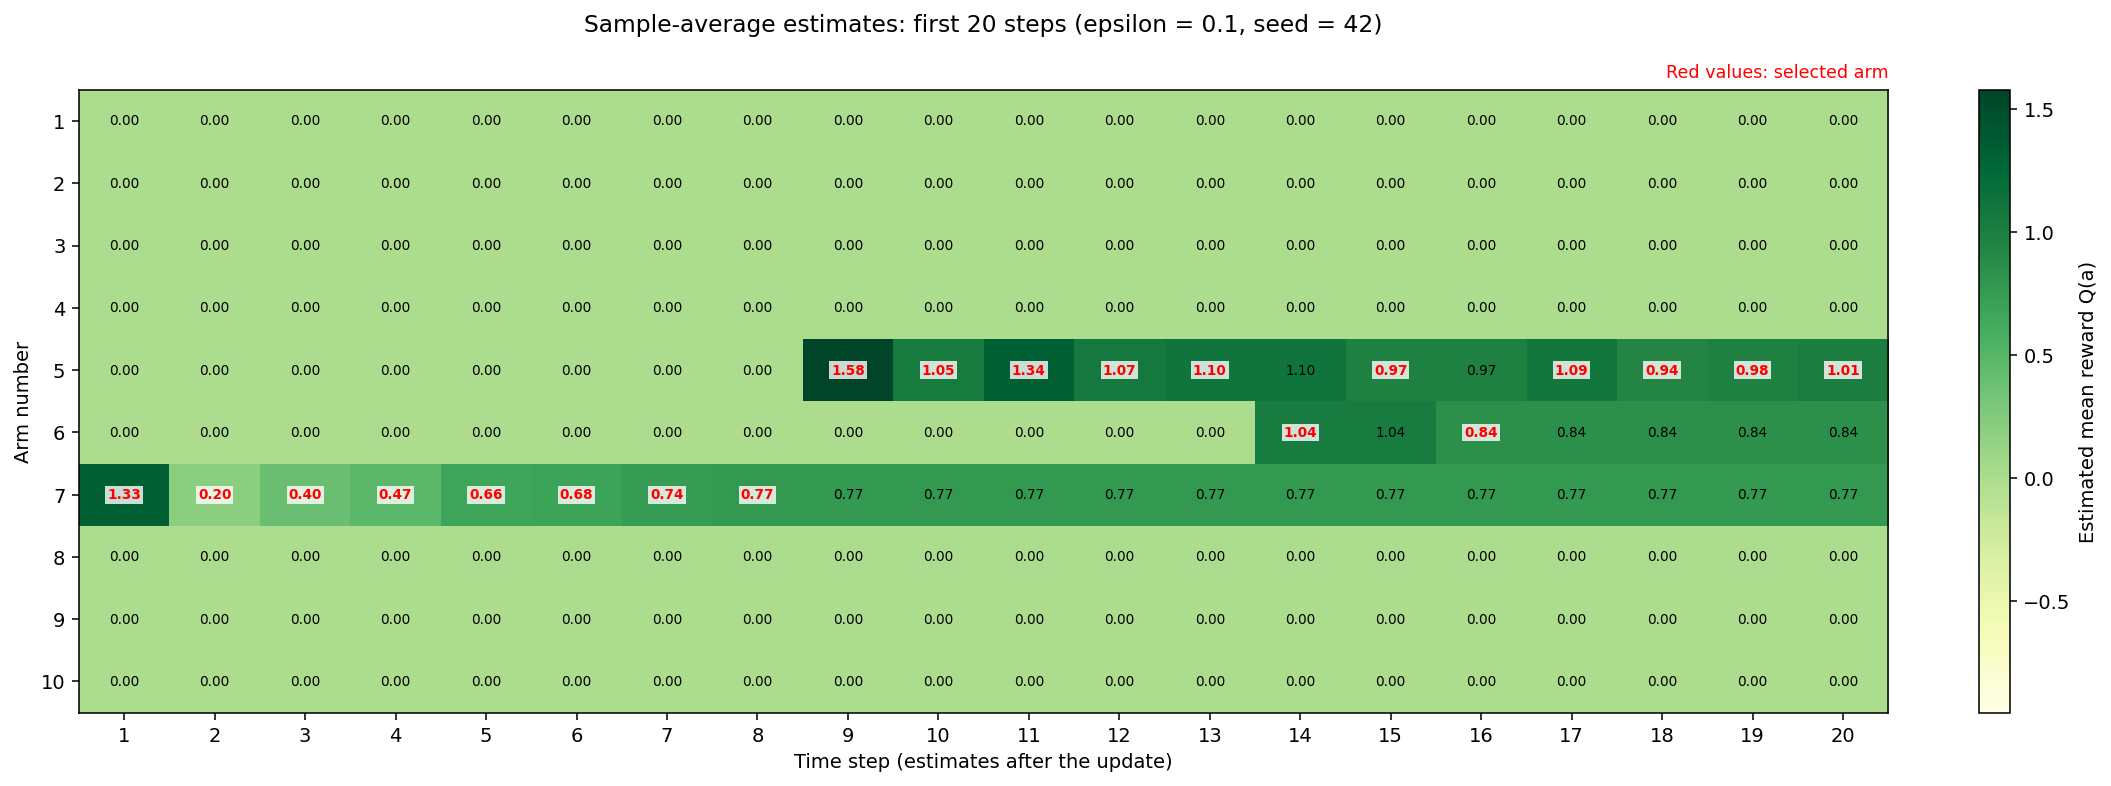

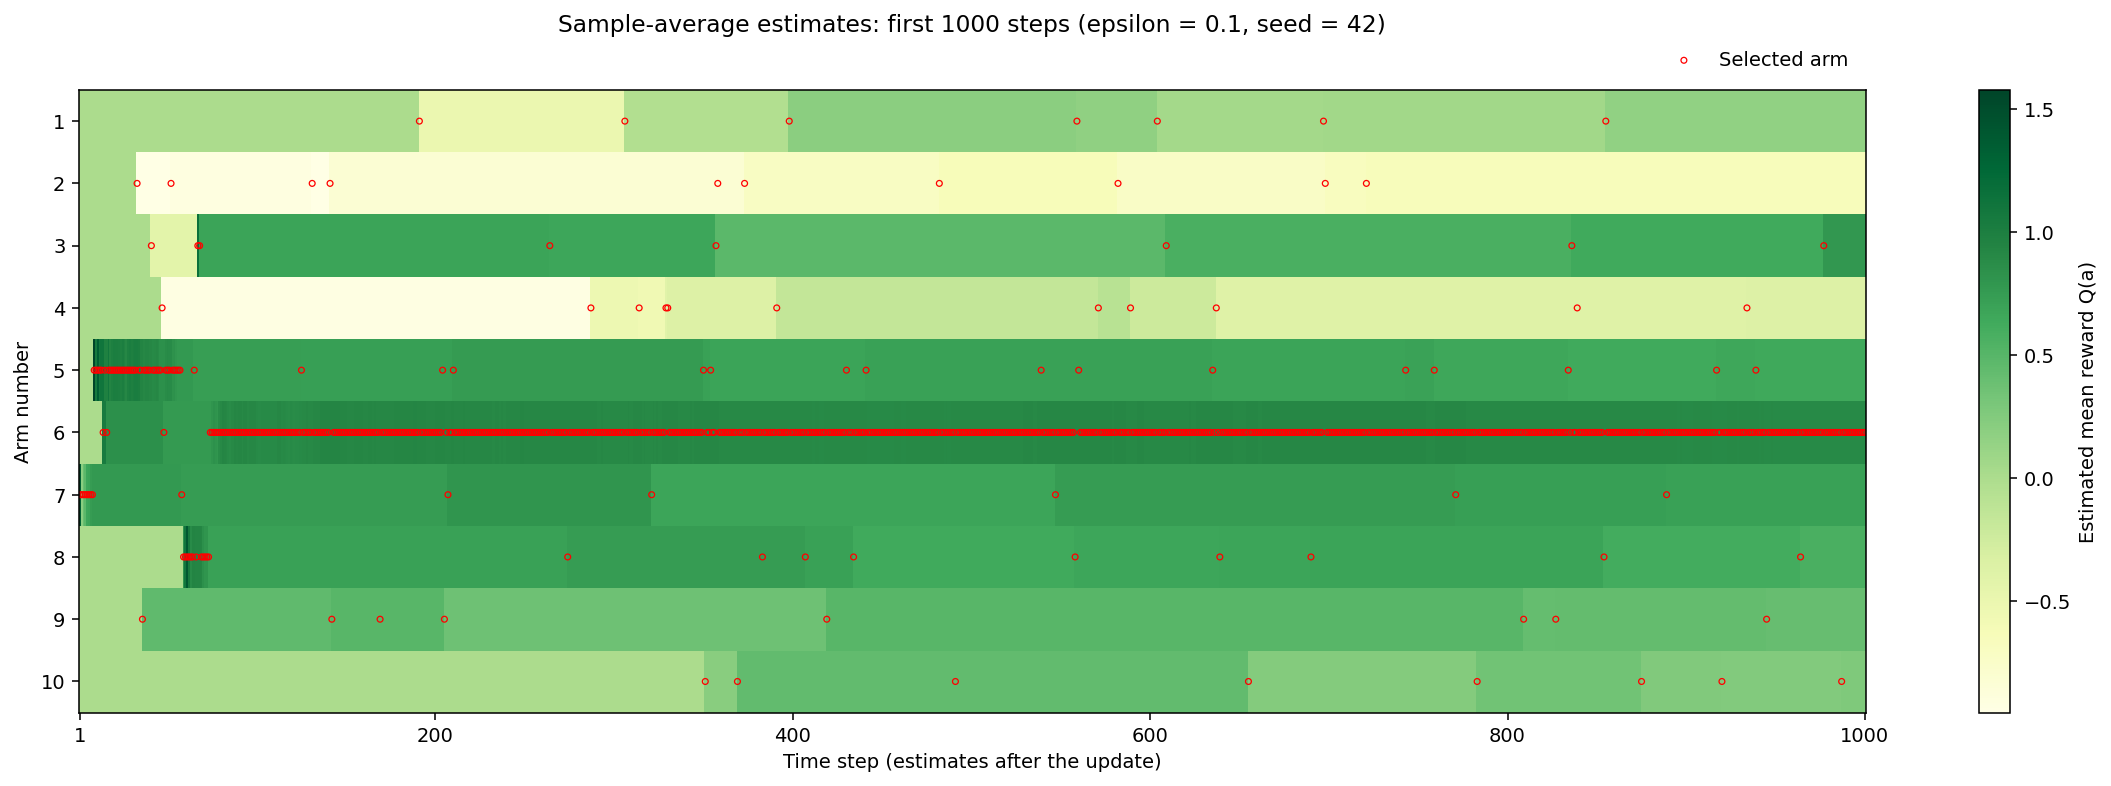

True optimal arm: 6 (mean reward = 0.9)
One run per policy, 1000 steps, seed = 42; displayed arms are numbered 1-10.

Arm  True mean  Q (epsilon=0.1)  Count (0.1)  Q (epsilon=0)  Count (0)
  1       0.20           0.1556            7         0.0000          0
  2      -0.70          -0.6549           10         0.0000          0
  3       0.50           0.7799            8         0.0000          0
  4      -0.30          -0.3646           11         0.0000          0
  5       0.70           0.6402           57         0.0000          0
  6       0.90           0.8903          856         0.0000          0
  7       0.70           0.7009           14         0.6636       1000
  8       0.60           0.5791           21         0.0000          0
  9       0.40           0.4020            8         0.0000          0
 10       0.30           0.2636            8         0.0000          0

epsilon=0.1: optimal-arm selections = 856/1000 (85.6%); realized mean reward = 0.8226; final greedy 

In [2]:
result_a = simulate_bandit(epsilon=0.1, steps=1000, seed=42)
result_greedy = simulate_bandit(epsilon=0.0, steps=1000, seed=42)
actions_a = result_a['actions']
rewards_a = result_a['rewards']
q_history_a = result_a['q_history']

plot_estimates(result_a, horizon=20, annotate=True)
plot_estimates(result_a, horizon=1000)

optimal_arm = int(np.argmax(MEANS))
print('True optimal arm: 6 (mean reward = 0.9)')
print('One run per policy, 1000 steps, seed = 42; displayed arms are numbered 1-10.\n')
print('Arm  True mean  Q (epsilon=0.1)  Count (0.1)  Q (epsilon=0)  Count (0)')
for arm in range(10):
    print(f'{arm + 1:>3}  {MEANS[arm]:>9.2f}  '
          f'{result_a["q_history"][-1, arm]:>15.4f}  '
          f'{result_a["counts"][arm]:>11d}  '
          f'{result_greedy["q_history"][-1, arm]:>13.4f}  '
          f'{result_greedy["counts"][arm]:>9d}')
for result in (result_a, result_greedy):
    best_estimated = np.flatnonzero(result['q_history'][-1] == result['q_history'][-1].max()) + 1
    optimal_count = int(np.sum(result['actions'] == optimal_arm))
    print(f'\nepsilon={result["epsilon"]:.1f}: '
          f'optimal-arm selections = {optimal_count}/1000 ({optimal_count / 10:.1f}%); '
          f'realized mean reward = {result["rewards"].mean():.4f}; '
          f'final greedy arm(s) = {best_estimated.tolist()}; '
          f'untried arms = {int(np.sum(result["counts"] == 0))}')


**“Discuss what happens if we always select the greedy action (i.e., $\varepsilon=0$).”**

With $\varepsilon=0$, the learner always chooses an arm with the highest current estimate, breaking ties randomly. The initial choice is random because all estimates are zero. After an arm obtains a uniquely positive estimate, untried arms can be ignored. A lucky early reward can therefore favor a suboptimal arm, while a poor observation can discourage the true best arm. Random tie-breaking alone does not provide continued exploration.

As we see above, my greedy-only run stayed on arm 7 and never discovered the optimal arm 6. The $\varepsilon=0.1$ run instead sampled every arm and eventually concentrated on arm 6, whose final estimate was close to its true mean. These individual trajectories illustrate why exploration matters; they do not establish average performance across runs.

The 20-step plot shows that unselected estimates remain unchanged while early observations can cause large corrections. Over 1,000 steps, frequent observations make the preferred arm's estimate more reliable, but rarely selected arms can remain inaccurately estimated. Continuing exploration corrects neglected estimates at the cost of occasionally selecting inferior arms. Once arm 6 is uniquely greedy, its selection probability is $0.9+0.1/10=91\%$; the fraction over the whole learning trajectory need not equal that value.


#### Part 1(b)

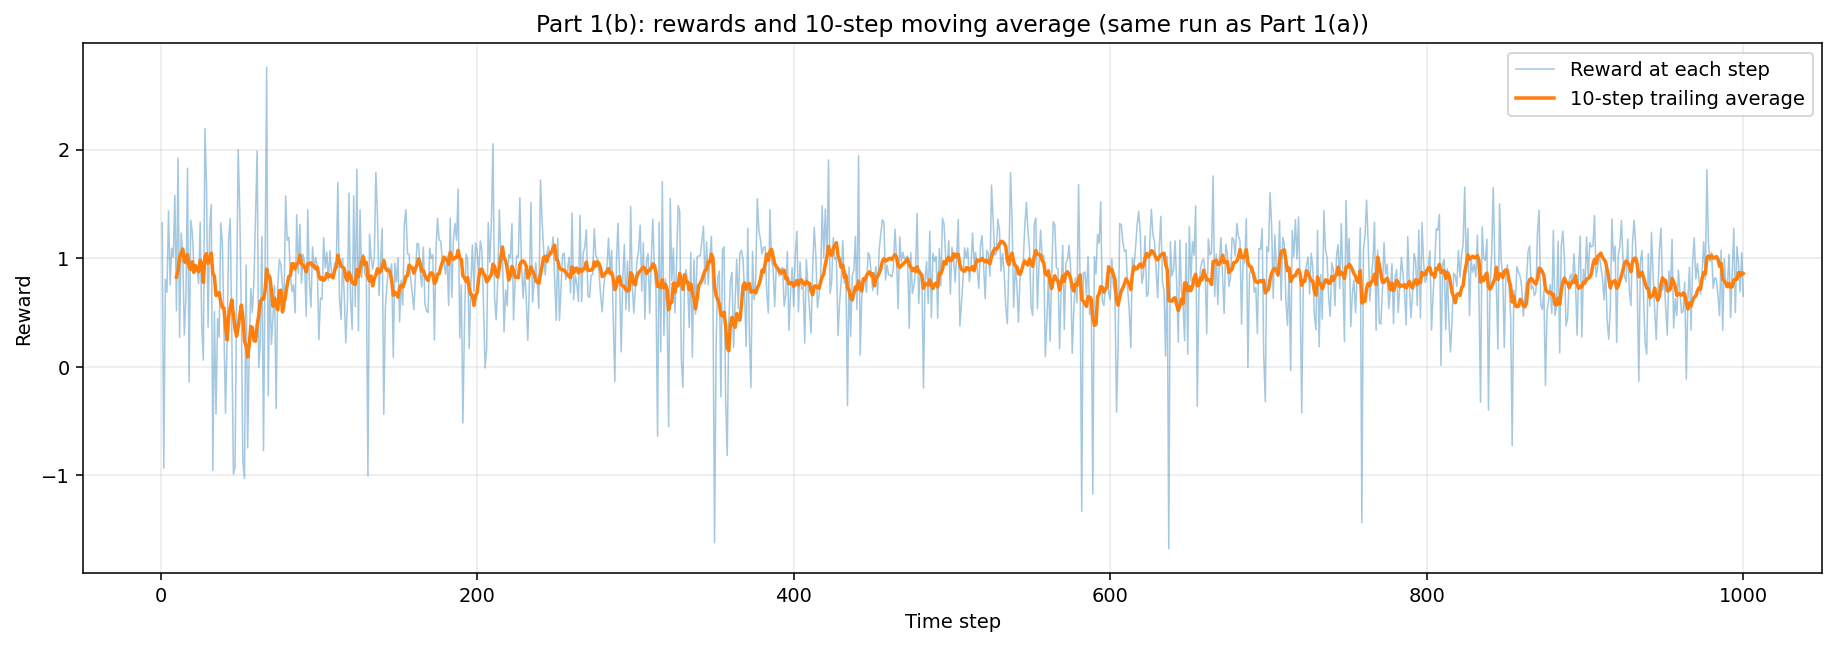

In [3]:
window_size = 10
# reuse the same run
time = np.arange(1, len(rewards_a) + 1)
moving_average_b = np.convolve(
    rewards_a, np.ones(window_size) / window_size, mode='valid'
)
# first window ends at step 10
window_end_steps = time[window_size - 1:]

fig, ax = plt.subplots(figsize=(13, 4.5), layout='constrained')
ax.plot(time, rewards_a, color='tab:blue', alpha=0.4, linewidth=0.8,
        label='Reward at each step')
ax.plot(window_end_steps, moving_average_b, color='tab:orange', linewidth=1.8,
        label='10-step trailing average')
ax.set(xlabel='Time step', ylabel='Reward',
       title='Part 1(b): rewards and 10-step moving average (same run as Part 1(a))')
ax.legend()
ax.grid(alpha=0.25)
plt.show()


The blue and orange curves use the same trajectory as (a): individual observed rewards and their ten-step trailing average,

$$
M_t=\frac{1}{10}\sum_{i=t-9}^{t}R_i,\qquad t\ge10.
$$

The average begins at step 10, when a complete window first exists. It reduces short-term fluctuations while retaining changes in the recent reward level. Remaining dips can reflect both Gaussian reward noise and exploration of inferior arms.

A steady rise is not expected in every individual run. This trajectory begins with some favorable rewards, and much of the later behavior is a noisy plateau after the learner favors arm 6. Learning improves the choices; it does not increase the arms' fixed true means. The moving average only summarizes the observed rewards and does not affect learning.


#### Part 1(c)

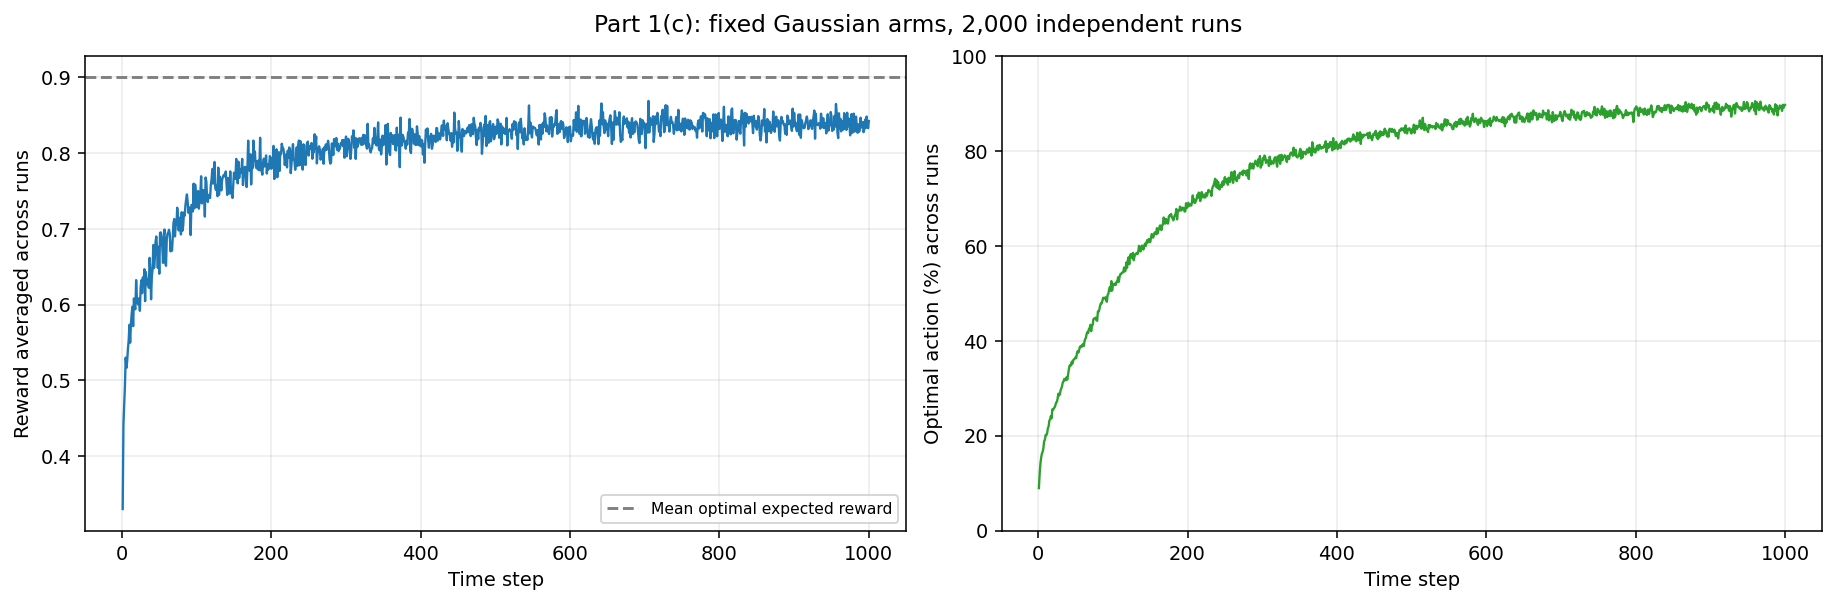

Independent runs: 2000; steps per run: 1000; epsilon = 0.1
Mean reward over all runs and steps: 0.8045
Mean reward at step 1000: 0.8423
Optimal actions at step 1000: 89.65%
Mean reward over the last 100 steps and all runs: 0.8389
Optimal actions over the last 100 steps and all runs: 89.04%


In [4]:
N_RUNS = 2000
N_STEPS = 1000
EPSILON = 0.1

# fixed environment across runs
fixed_means_c = np.tile(MEANS, (N_RUNS, 1))
result_c = simulate_many(fixed_means_c, VARIANCES, steps=N_STEPS,
                         epsilon=EPSILON, seed=2026)
plot_performance(result_c,
                 'Part 1(c): fixed Gaussian arms, 2,000 independent runs')
print_performance(result_c)


As the plots above show, average reward and optimal-action selection improve across the repeated fixed-arm experiments. Each point averages the 2,000 runs at the same time step; it is not a cumulative or moving average. Arm 6 is optimal in every run.

The late-stage reward is close to the expected reward of a learner that has identified arm 6 but still explores. Its expected reward is

$$
0.9(0.9)+0.1\left(\frac{1}{10}\sum_a\mu_a\right)
=0.843,
$$

below the dashed best-arm reference of 0.9. The corresponding optimal-selection probability is 91%, since exploration can also select the best arm. Persistent exploration therefore explains why good learning does not produce 100% optimal selections. Remaining differences from these references reflect finite-sample estimation errors and reward noise. Averaging across runs makes the learning trend clearer than the individual trajectory in (b).


#### Part 1(d)

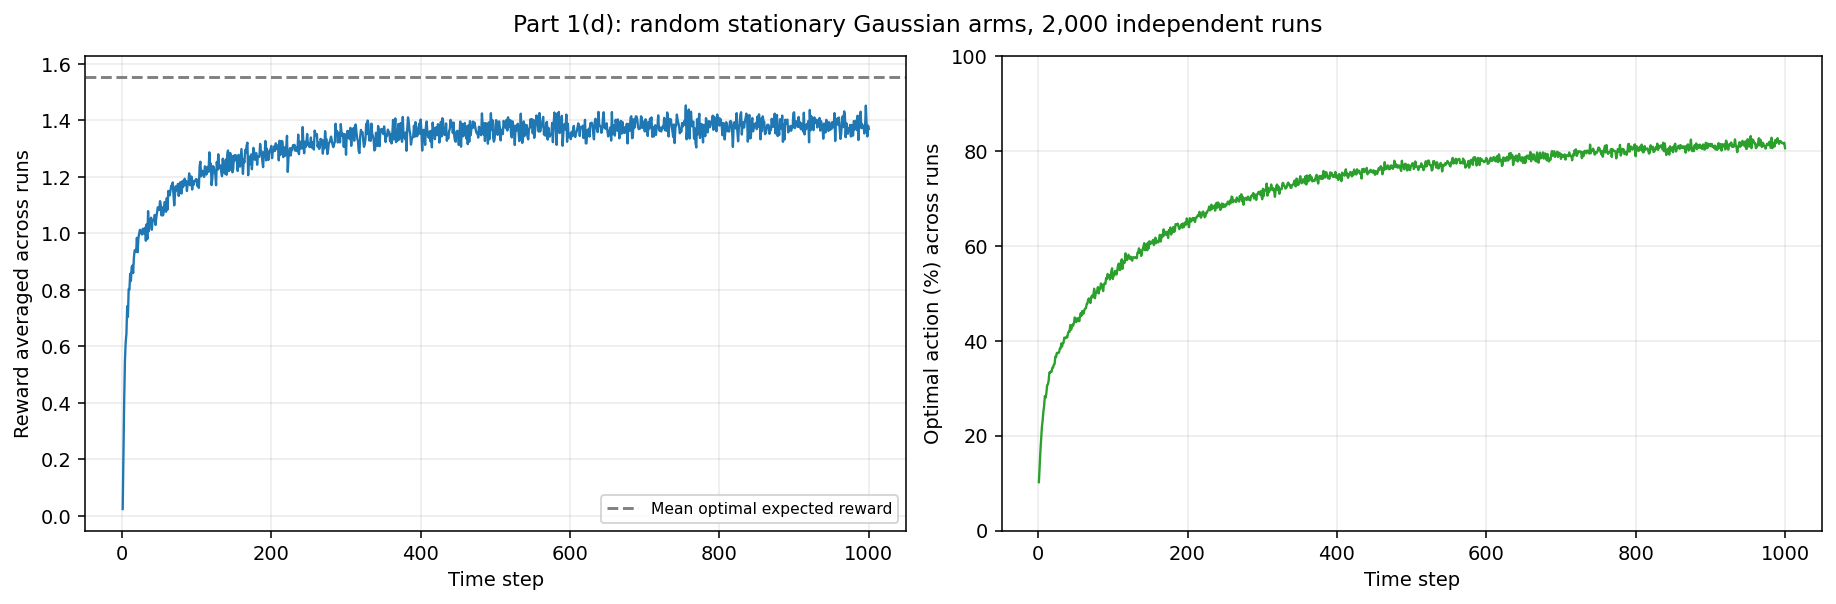

Independent runs: 2000; steps per run: 1000; epsilon = 0.1
Mean reward over all runs and steps: 1.3196
Mean reward at step 1000: 1.3697
Optimal actions at step 1000: 80.55%
Mean reward over the last 100 steps and all runs: 1.3820
Optimal actions over the last 100 steps and all runs: 81.32%


In [5]:
# fixed means within each run
environment_rng = np.random.default_rng(2027)
random_means_d = environment_rng.normal(loc=0.0, scale=1.0, size=(N_RUNS, 10))
result_d = simulate_many(random_means_d, np.ones(10), steps=N_STEPS,
                         epsilon=EPSILON, seed=2028)
plot_performance(result_d,
                 'Part 1(d): random stationary Gaussian arms, 2,000 independent runs')
print_performance(result_d)


Here, each run has a separate set of true means sampled from $\mathcal N(0,1)$, with reward variance 1. The means remain fixed within each run, and optimal choices are evaluated against that run's own best arm. This tests learning across different stationary bandit problems.

As we see above, both curves improve from an initially near-random policy. The late-stage reward remains below the dashed average optimal-mean reference because exploration continues and some learners still favor an incorrectly estimated best arm. Likewise, the optimal-selection rate remains below the 91% reference for consistently correct greedy choices. Reward noise and small gaps between competing arms can delay reliable identification.

The reward is higher than in (c), despite a lower optimal-selection percentage. This does not establish better decision-making: the distribution of true means and the attainable rewards changed. I therefore interpret the learning trend and optimal-selection rate within each environment setting, rather than comparing raw rewards alone.


### Part 2


#### Part 2(a)


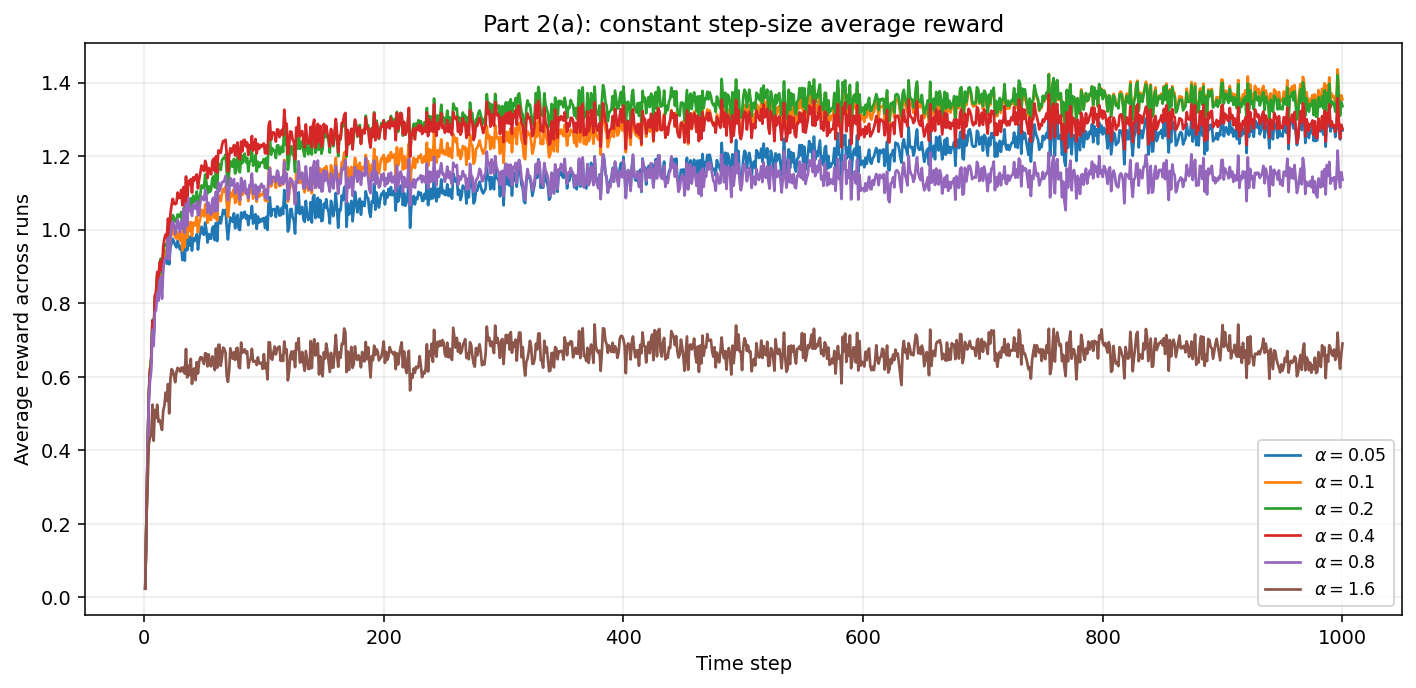

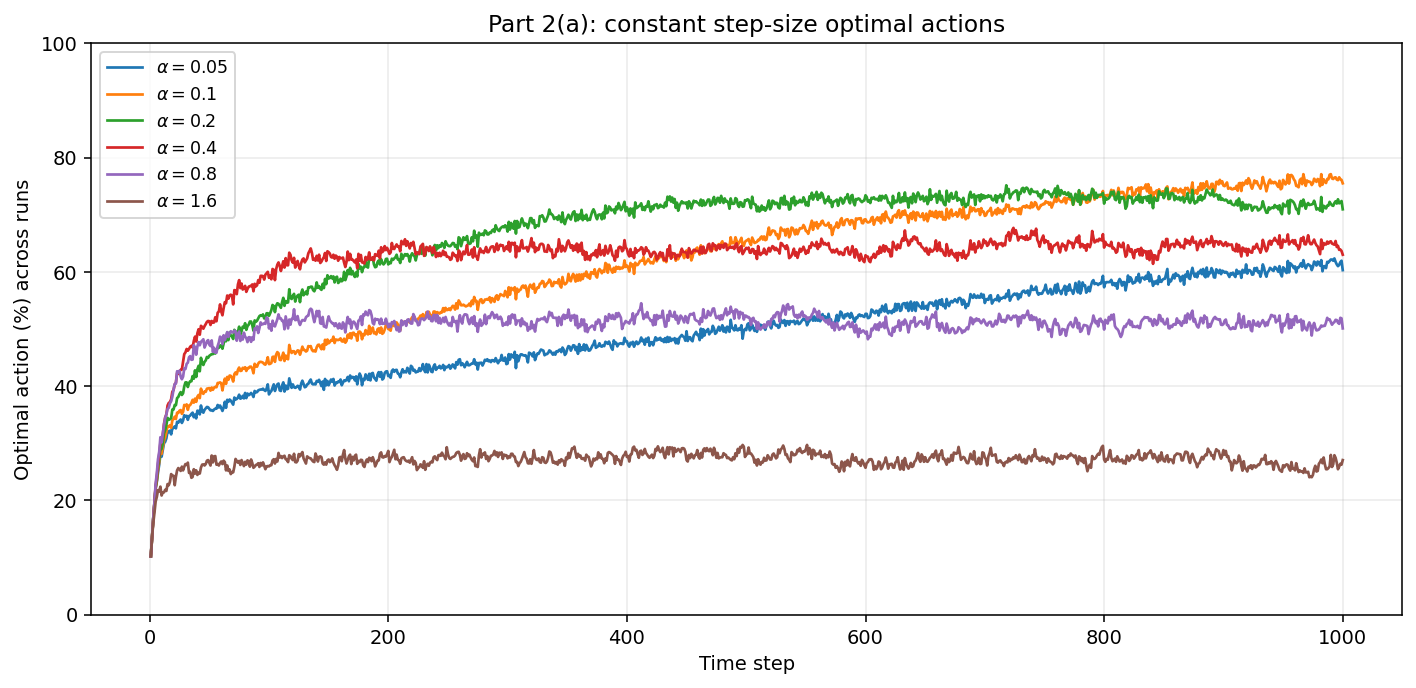

alpha | mean reward (1-1000) | mean reward (901-1000) | optimal actions (901-1000)
 0.05 |               1.1604 |                 1.2726 |                     60.61%
  0.1 |               1.2626 |                 1.3636 |                     75.63%
  0.2 |               1.3026 |                 1.3470 |                     71.60%
  0.4 |               1.2681 |                 1.2920 |                     64.68%
  0.8 |               1.1302 |                 1.1419 |                     50.96%
  1.6 |               0.6599 |                 0.6550 |                     26.11%
Best alpha by mean reward over 1,000 steps: 0.2


In [6]:
q1_alphas = [0.05, 0.1, 0.2, 0.4, 0.8, 1.6]
q1_constant_results = {}
for alpha in q1_alphas:
    q1_constant_results[alpha] = q1_update_runs(random_means_d, alpha=alpha)

q1_best_alpha = max(q1_alphas,
                    key=lambda alpha: q1_constant_results[alpha]['average_reward'].mean())
q1_constant_curves = {rf'$\alpha={alpha:g}$': result
                      for alpha, result in q1_constant_results.items()}
q1_plot_comparison(q1_constant_curves, 'average_reward',
                   'Part 2(a): constant step-size average reward', 'part_2/subpart_a/average_reward.png')
q1_plot_comparison(q1_constant_curves, 'optimal_percent',
                   'Part 2(a): constant step-size optimal actions', 'part_2/subpart_a/optimal_actions.png')

print('alpha | mean reward (1-1000) | mean reward (901-1000) | optimal actions (901-1000)')
for alpha, result in q1_constant_results.items():
    print(f'{alpha:>5g} | {result["average_reward"].mean():>20.4f} | '
          f'{result["average_reward"][-100:].mean():>22.4f} | '
          f'{result["optimal_percent"][-100:].mean():>25.2f}%')
print(f'Best alpha by mean reward over 1,000 steps: {q1_best_alpha:g}')


**“Determine which value of $\alpha$ yields the best performance. What happens if $\alpha$ is too low or too high?”**

To select one setting for the next comparison, I used average reward over the full 1,000-step horizon. As the output above shows, **$\alpha=0.2$ performs best by that criterion**. However, $\alpha=0.1$ gives the strongest late-stage reward and optimal-action percentage. The preferred value therefore depends on how much weight is placed on initial learning versus later performance.

When $\alpha$ is too small, each reward makes only a small correction. Initial estimates persist longer, and infrequently selected arms can take considerable time to learn; the slow improvement for $\alpha=0.05$ illustrates this. Increasing $\alpha$ initially improves responsiveness, but a large constant update also retains more reward noise, which can repeatedly change the greedy choice.

At $\alpha=1.6$, the rule becomes $Q_{t+1}=-0.6Q_t+1.6R_t$, so an update can overshoot the observed reward. Its poor curve reflects overly aggressive, noisy corrections; it does not by itself demonstrate divergence. Overall, the plots favor moderate step sizes over either extreme for this stationary experiment.


#### Part 2(b)


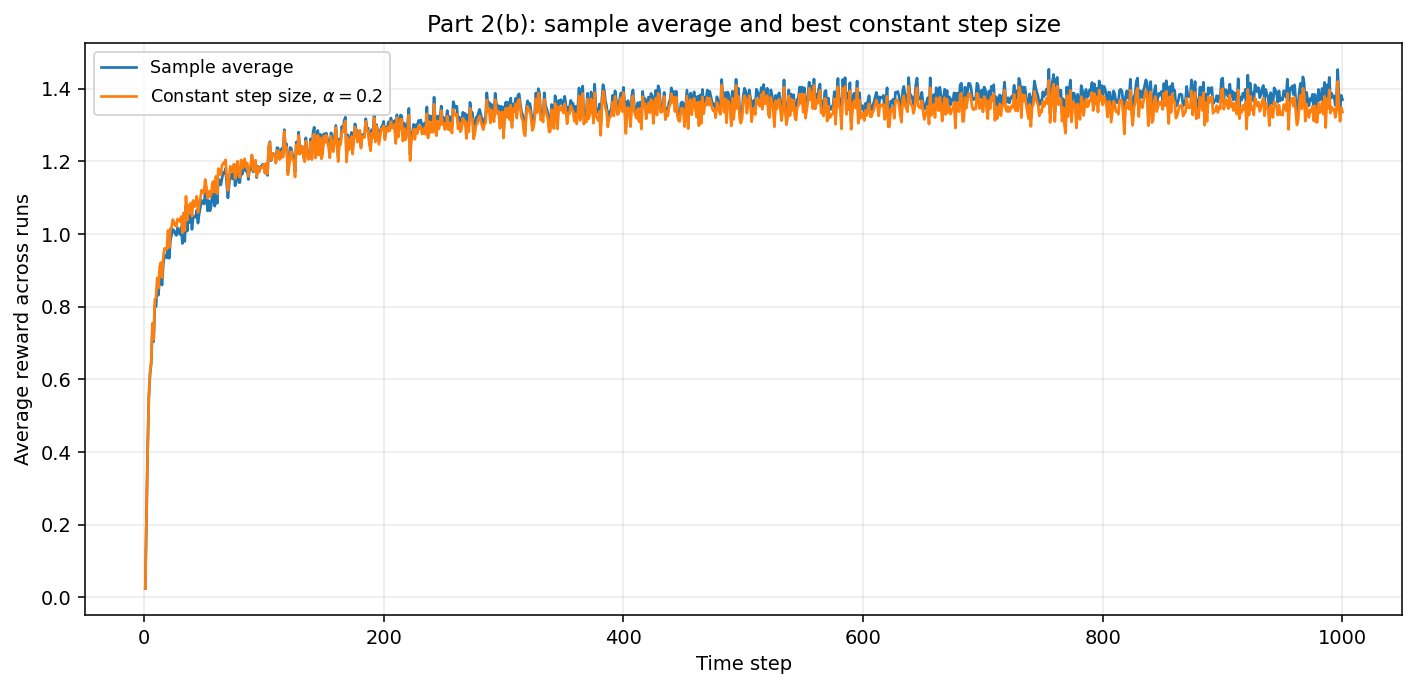

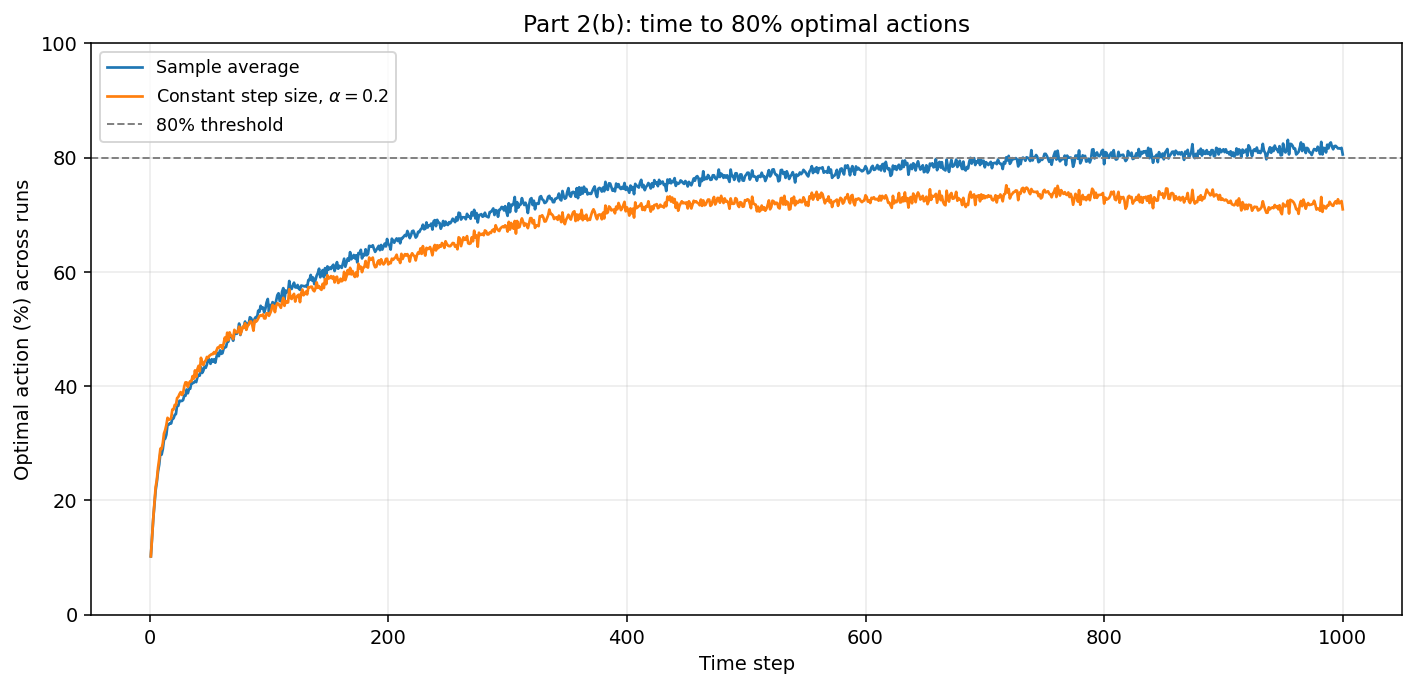

Sample average: first step with at least 80% optimal actions = 718
Constant step size, $\alpha=0.2$: first step with at least 80% optimal actions = not reached within 1,000 steps


In [7]:
q1_method_comparison = {
    'Sample average': result_d,
    rf'Constant step size, $\alpha={q1_best_alpha:g}$': q1_constant_results[q1_best_alpha],
}
q1_plot_comparison(q1_method_comparison, 'average_reward',
                   'Part 2(b): sample average and best constant step size',
                   'part_2/subpart_b/average_reward.png')
q1_plot_comparison(q1_method_comparison, 'optimal_percent',
                   'Part 2(b): time to 80% optimal actions',
                   'part_2/subpart_b/optimal_actions.png', threshold=True)

q1_first_80 = {}
for label, result in q1_method_comparison.items():
    reached = np.flatnonzero(result['optimal_percent'] >= 80)
    q1_first_80[label] = int(reached[0] + 1) if reached.size else None
    crossing = str(q1_first_80[label]) if reached.size else 'not reached within 1,000 steps'
    print(f'{label}: first step with at least 80% optimal actions = {crossing}')


**“Evaluate and compare the time required to reach an 80% probability of selecting the optimal action for both the constant step-size and average-reward algorithms. Determine which method converges faster to the best arm.”**

The figures compare Part 1(d)'s sample-average method with the selected constant step size, $\alpha=0.2$, using the same environments, exploration rate, and reward-noise draws. The empirical crossing time is the first unsmoothed time step at which at least 80% of runs choose their own optimal arm.

As reported above, **the sample-average method reaches the threshold at step 718**, while the constant-step-size method does not reach it within 1,000 steps. The sample average therefore meets the requested criterion faster in this experiment. No crossing time is assigned to the other method beyond the observed horizon, and the first crossing need not imply that every later point stays above 80%.

The constant-step-size method initially learns competitively, but its optimal-action curve levels off below the threshold. Sample-average updates shrink as observations accumulate, progressively reducing the influence of reward noise in this stationary setting. Constant updates remain responsive but preserve more estimate variability. The comparison distinguishes rapid initial improvement from reaching a reliable level of optimal-action selection.


### Part 3


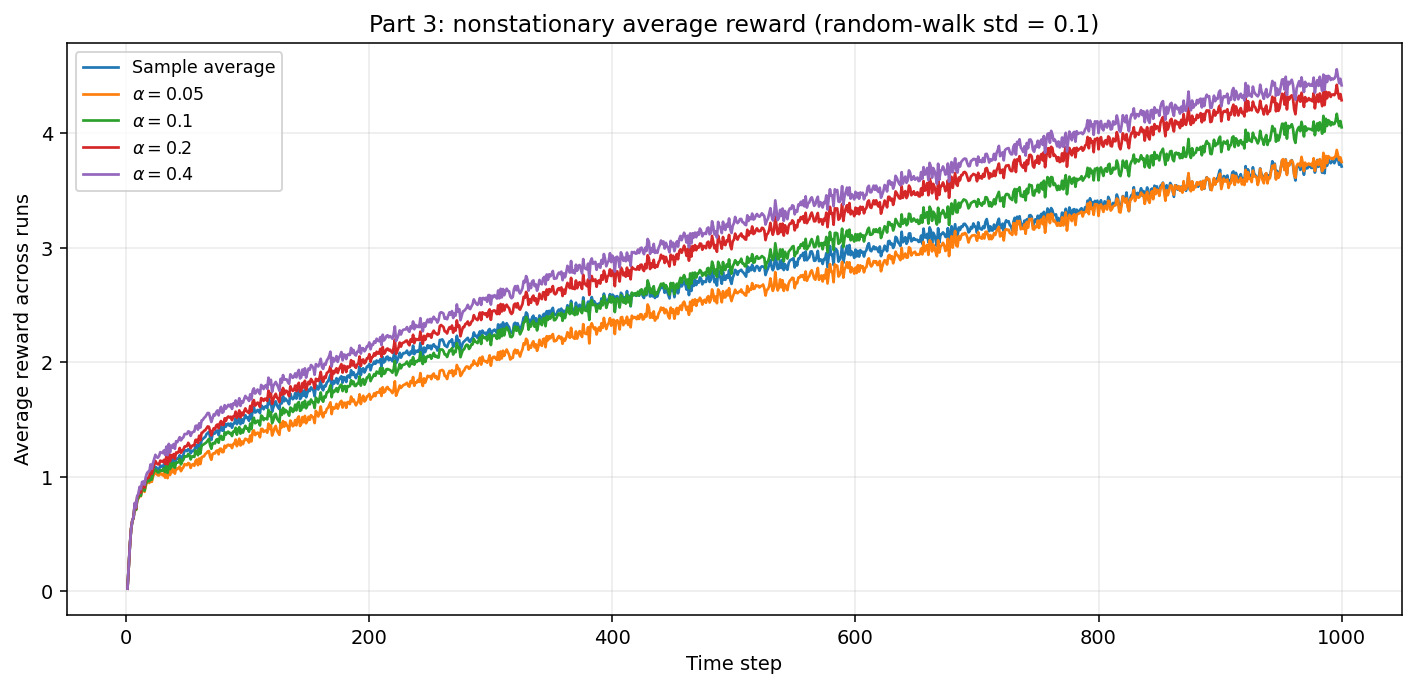

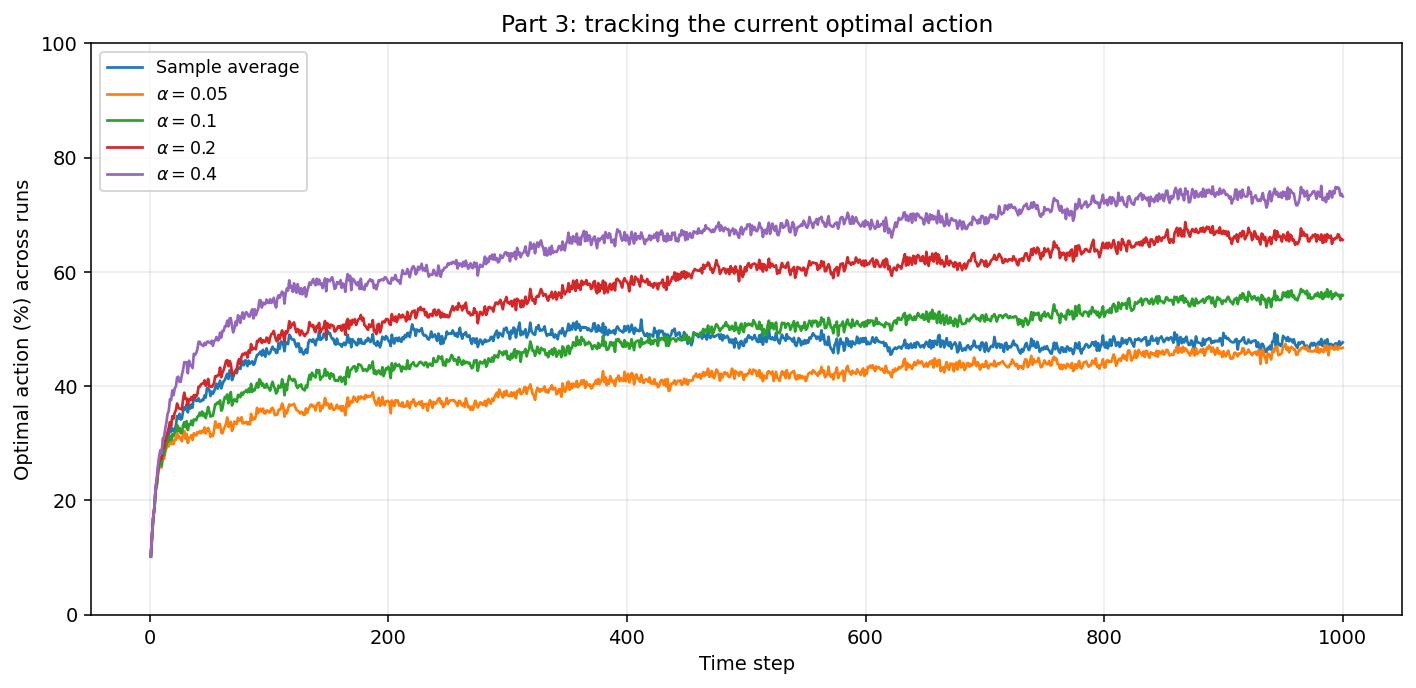

method | mean reward (1-1000) | mean reward (901-1000) | optimal actions (901-1000)
 Sample average |               2.6508 |                 3.6779 |                     47.53%
  $\alpha=0.05$ |               2.5165 |                 3.6778 |                     46.07%
   $\alpha=0.1$ |               2.7448 |                 4.0004 |                     55.61%
   $\alpha=0.2$ |               2.9586 |                 4.2595 |                     66.05%
   $\alpha=0.4$ |               3.0850 |                 4.3937 |                     73.40%


In [8]:
q1_nonstationary_results = {
    'Sample average': q1_update_runs(random_means_d, walk_std=0.1),
}
for alpha in [0.05, 0.1, 0.2, 0.4]:
    q1_nonstationary_results[rf'$\alpha={alpha:g}$'] = q1_update_runs(
        random_means_d, alpha=alpha, walk_std=0.1)

q1_plot_comparison(q1_nonstationary_results, 'average_reward',
                   'Part 3: nonstationary average reward (random-walk std = 0.1)',
                   'part_3/average_reward.png')
q1_plot_comparison(q1_nonstationary_results, 'optimal_percent',
                   'Part 3: tracking the current optimal action', 'part_3/optimal_actions.png')

print('method | mean reward (1-1000) | mean reward (901-1000) | optimal actions (901-1000)')
for label, result in q1_nonstationary_results.items():
    print(f'{label:>15} | {result["average_reward"].mean():>20.4f} | '
          f'{result["average_reward"][-100:].mean():>22.4f} | '
          f'{result["optimal_percent"][-100:].mean():>25.2f}%')


**“Compare the performance of these two algorithms in the non-stationary environment.”**

The assignment's prose gives random-walk variance 0.1, whereas its equation specifies $\mathcal N(0,0.1^2)$. I followed the explicit equation: increments have standard deviation 0.1 and variance 0.01. Every arm's mean changes after each interaction, and optimal selections are measured against the current best arm. All methods experience the same initial means, drift paths, and reward-noise draws.

The plots above favor **$\alpha=0.4$ among the tested settings**, both in reward and in selecting the current optimal arm. Its larger corrections track changes more effectively. The sample average retains all past rewards with equal weight and becomes less responsive as its step size shrinks; old observations can therefore describe means that are no longer current. Constant steps discount older information and keep responding to changes. However, a very small constant step can still be too slow, as the $\alpha=0.05$ results demonstrate.

The advantage of larger steps here depends on the specified drift and tested values, rather than implying that increasing $\alpha$ always helps. Also, random walks spread the means apart over time, increasing the expected best available reward. Rising reward curves alone therefore do not prove improving tracking; the optimal-action plot more directly shows the benefit of the larger constant steps.


## Question 2: The 10-Armed Bandit Problem


### General Setup

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Q2_RUNS = 2000
Q2_STEPS = 500
Q2_ARMS = 10
Q2_PLOTS = Path('results') / 'question_2'

q2_environment_rng = np.random.default_rng(20261017)
q2_means = q2_environment_rng.normal(0.0, 1.0, size=(Q2_RUNS, Q2_ARMS))
q2_noise = q2_environment_rng.normal(0.0, 1.0, size=(Q2_RUNS, Q2_STEPS))


def q2_random_argmax(values, rng):
    """random tie-breaking."""
    tied = values == values.max(axis=1, keepdims=True)
    return np.argmax(np.where(tied, rng.random(values.shape), -1.0), axis=1)


def q2_value_run(means, noise, method, parameter, seed=7101):
    """sample-average bandits."""
    rng = np.random.default_rng(seed)
    n_runs, n_arms = means.shape
    n_steps = noise.shape[1]
    rows = np.arange(n_runs)
    estimates = np.zeros((n_runs, n_arms))
    counts = np.zeros((n_runs, n_arms), dtype=int)
    optimal = means.argmax(axis=1)
    optimal_mean = means[rows, optimal]
    average_reward = np.empty(n_steps)
    optimal_percent = np.empty(n_steps)
    average_regret = np.empty(n_steps)

    for step in range(n_steps):
        if method == 'epsilon':
            greedy = q2_random_argmax(estimates, rng)
            explore = rng.random(n_runs) < parameter
            random_actions = rng.integers(n_arms, size=n_runs)
            chosen = np.where(explore, random_actions, greedy)
        else:
            # untried arms have priority
            bonus = parameter * np.sqrt(np.log(step + 1) / np.maximum(counts, 1))
            scores = np.where(counts == 0, np.inf, estimates + bonus)
            chosen = q2_random_argmax(scores, rng)

        reward = means[rows, chosen] + noise[:, step]
        counts[rows, chosen] += 1
        estimates[rows, chosen] += (reward - estimates[rows, chosen]) / counts[rows, chosen]
        average_reward[step] = reward.mean()
        optimal_percent[step] = 100 * (chosen == optimal).mean()
        average_regret[step] = (optimal_mean - means[rows, chosen]).mean()

    return {
        'average_reward': average_reward,
        'optimal_percent': optimal_percent,
        'cumulative_regret': np.cumsum(average_regret),
    }


def q2_gradient_run(means, noise, alpha, use_baseline, seed=7102):
    """gradient bandits."""
    rng = np.random.default_rng(seed)
    n_runs, n_arms = means.shape
    rows = np.arange(n_runs)
    n_steps = noise.shape[1]
    preferences = np.zeros((n_runs, n_arms))
    average_past_reward = np.zeros(n_runs)
    optimal = means.argmax(axis=1)
    average_reward = np.empty(n_steps)
    optimal_percent = np.empty(n_steps)

    for step in range(n_steps):
        # stable softmax
        shifted = preferences - preferences.max(axis=1, keepdims=True)
        exponentials = np.exp(shifted)
        probabilities = exponentials / exponentials.sum(axis=1, keepdims=True)
        cumulative = np.cumsum(probabilities, axis=1)
        cumulative[:, -1] = 1.0
        chosen = (rng.random(n_runs)[:, None] > cumulative).sum(axis=1)
        reward = means[rows, chosen] + noise[:, step]

        # baseline excludes the current reward
        baseline = average_past_reward if use_baseline else 0.0
        advantage = reward - baseline
        preferences -= alpha * advantage[:, None] * probabilities
        preferences[rows, chosen] += alpha * advantage
        average_past_reward += (reward - average_past_reward) / (step + 1)

        average_reward[step] = reward.mean()
        optimal_percent[step] = 100 * (chosen == optimal).mean()

    return {'average_reward': average_reward, 'optimal_percent': optimal_percent}


def q2_plot(results, metric, title, ylabel, filename, log_scale=False):
    """plot and save."""
    fig, ax = plt.subplots(figsize=(10, 4.8), layout='constrained')
    time = np.arange(1, Q2_STEPS + 1)
    for label, result in results.items():
        ax.plot(time, result[metric], label=label, linewidth=1.5,
                **result.get('style', {}))
    ax.set(xlabel='Time step', ylabel=ylabel, title=title)
    if metric == 'optimal_percent':
        ax.set_ylim(0, 100)
    if log_scale:
        ax.set_yscale('log')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
    destination = Q2_PLOTS / filename
    destination.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(destination, dpi=180, bbox_inches='tight')
    plt.show()


Q2's shared functions keep the simulation and plotting consistent across the three tasks, with 2,000 stationary environments and a 500-step horizon. I reuse the sampled environments and reward-noise draws across settings to reduce unrelated differences between comparisons. Task 3 shifts the true means by 5, starts preferences at zero, and uses the average of past rewards as its baseline. The task cells can then focus on their parameter settings, plots, and results.

### Task 1 — The ε-Greedy Algorithm

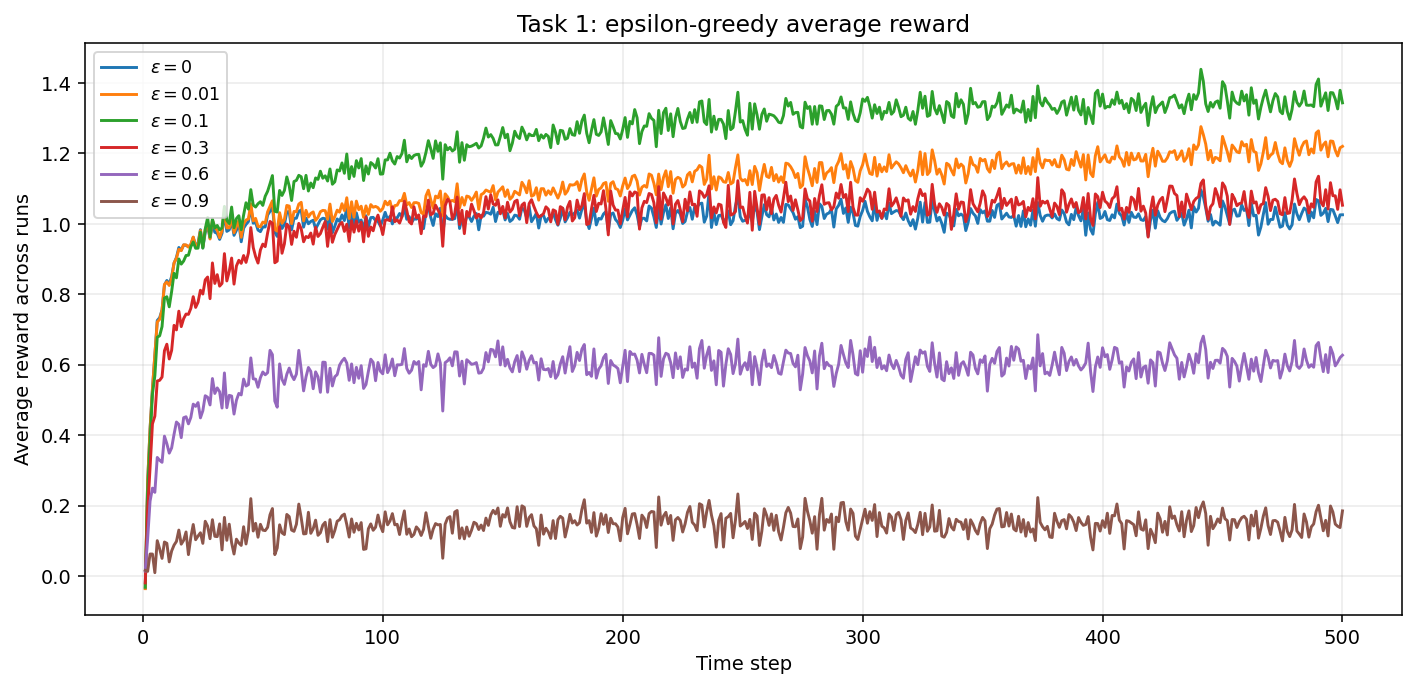

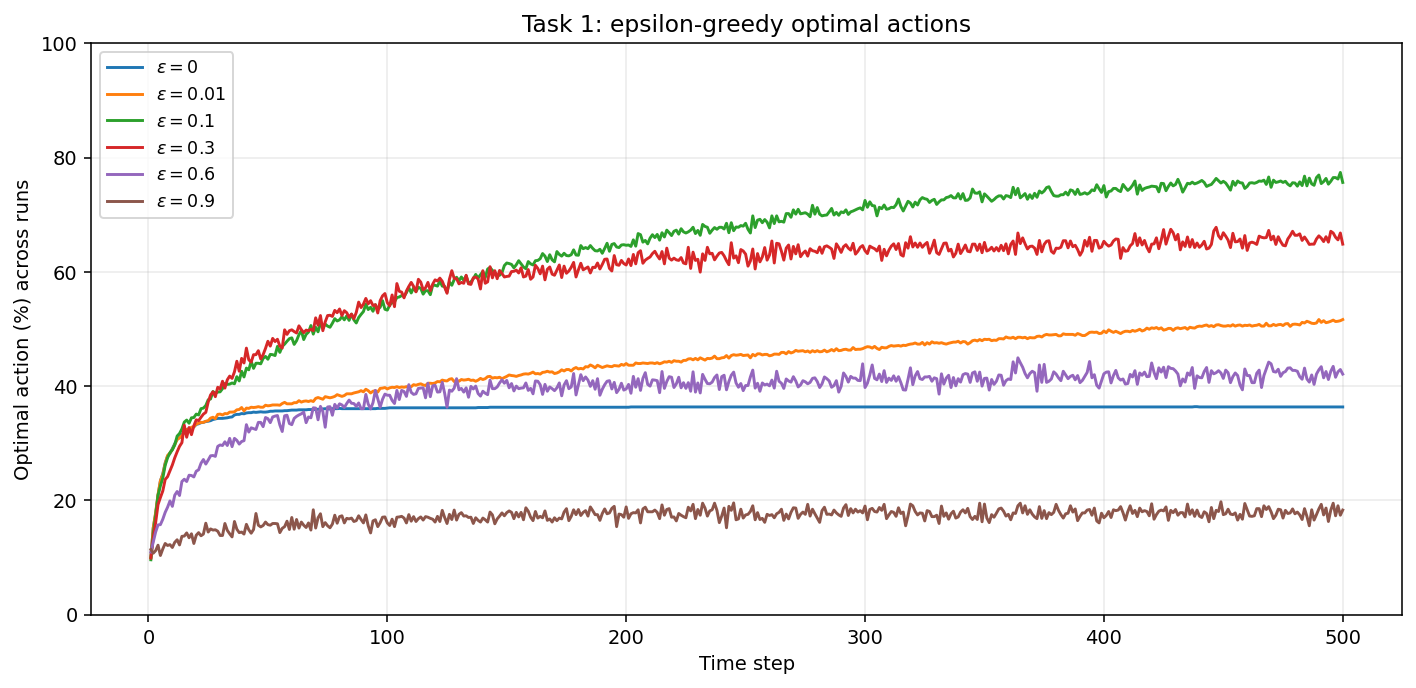

epsilon | mean reward (1-500) | mean reward (401-500) | optimal actions (401-500)
      0 |              1.0072 |                1.0233 |                    36.35%
   0.01 |              1.1095 |                1.2018 |                    50.46%
    0.1 |              1.2442 |                1.3465 |                    75.36%
    0.3 |              1.0144 |                1.0631 |                    65.44%
    0.6 |              0.5857 |                0.6066 |                    42.02%
    0.9 |              0.1441 |                0.1500 |                    17.87%


In [7]:
q2_epsilon_results = {}
for epsilon in [0, 0.01, 0.1, 0.3, 0.6, 0.9]:
    label = rf'$\varepsilon={epsilon:g}$'
    q2_epsilon_results[label] = q2_value_run(q2_means, q2_noise, 'epsilon', epsilon)

q2_plot(q2_epsilon_results, 'average_reward',
        'Task 1: epsilon-greedy average reward', 'Average reward across runs',
        'task_1/average_reward.png')
q2_plot(q2_epsilon_results, 'optimal_percent',
        'Task 1: epsilon-greedy optimal actions', 'Optimal action (%) across runs',
        'task_1/optimal_actions.png')

print('epsilon | mean reward (1-500) | mean reward (401-500) | optimal actions (401-500)')
for epsilon, result in zip([0, 0.01, 0.1, 0.3, 0.6, 0.9], q2_epsilon_results.values()):
    print(f'{epsilon:>7g} | {result["average_reward"].mean():>19.4f} | '
          f'{result["average_reward"][-100:].mean():>21.4f} | '
          f'{result["optimal_percent"][-100:].mean():>24.2f}%')


**“Explain the short-term and long-term impact of increasing $\varepsilon$. Which $\varepsilon$ performs best overall, and why?”**

In the short term, increasing $\varepsilon$ creates more opportunities to sample neglected arms and correct misleading initial estimates. It also incurs an immediate cost by selecting inferior arms randomly. The benefit is not monotonic: greedy learners can exploit favorable observations quickly, but many settle on suboptimal choices; very large exploration rates sacrifice too many reward opportunities.

As the curves and printed summary show, **$\varepsilon=0.1$ gives the highest average reward over the required 500 steps**, and also leads the late-stage measures. It balances useful exploration against its continuing cost. The greedy curve largely plateaus, while $\varepsilon=0.01$ continues improving more slowly. Values such as 0.6 and 0.9 explore frequently but exploit good discoveries too rarely.

Over long horizons, fixed positive exploration still selects inferior arms after learning. With a unique correctly identified best arm, the optimal-selection probability is

$$
1-\varepsilon+\frac{\varepsilon}{10}=1-0.9\varepsilon.
$$

Thus a larger $\varepsilon$ also lowers the limiting fraction of optimal choices. The best setting depends on the horizon: I selected 0.1 for this experiment, while a smaller positive value such as 0.01 can eventually benefit from its lower exploration cost in a much longer stationary run.


### Task 2 — UCB vs. ε-Greedy: Regret Comparison

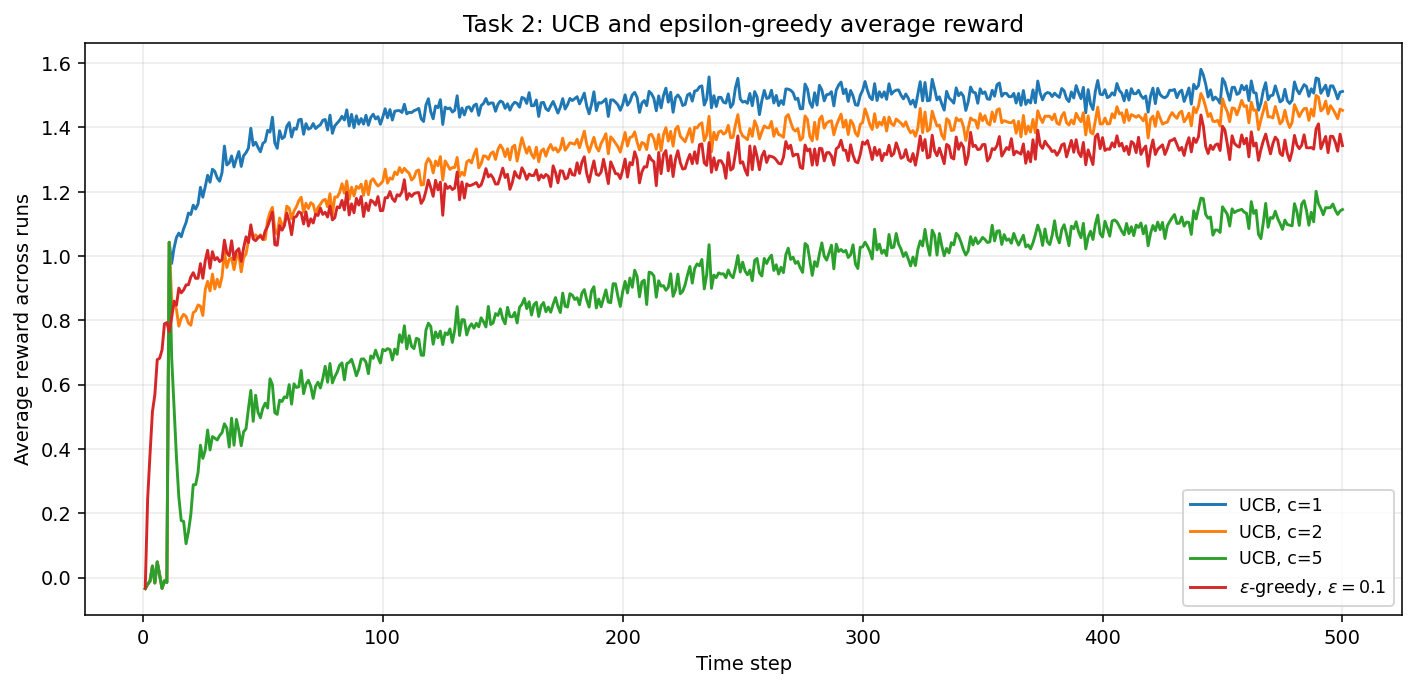

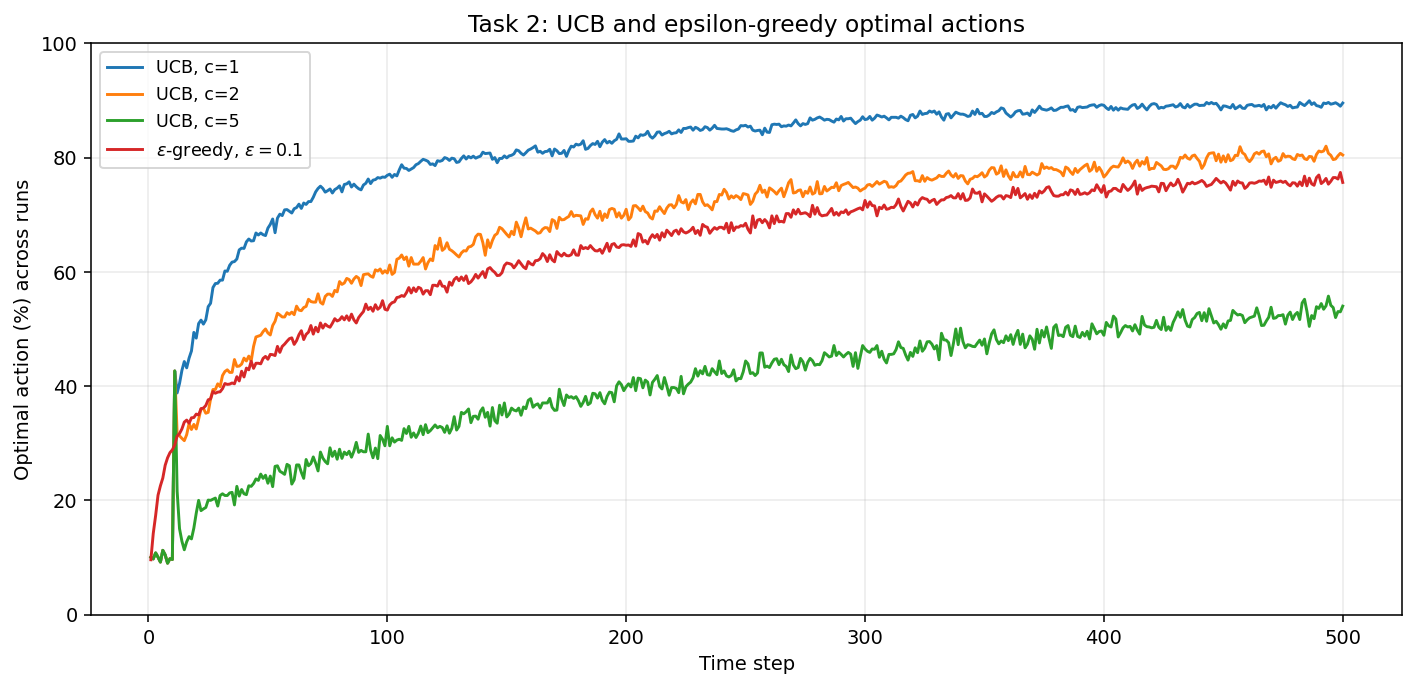

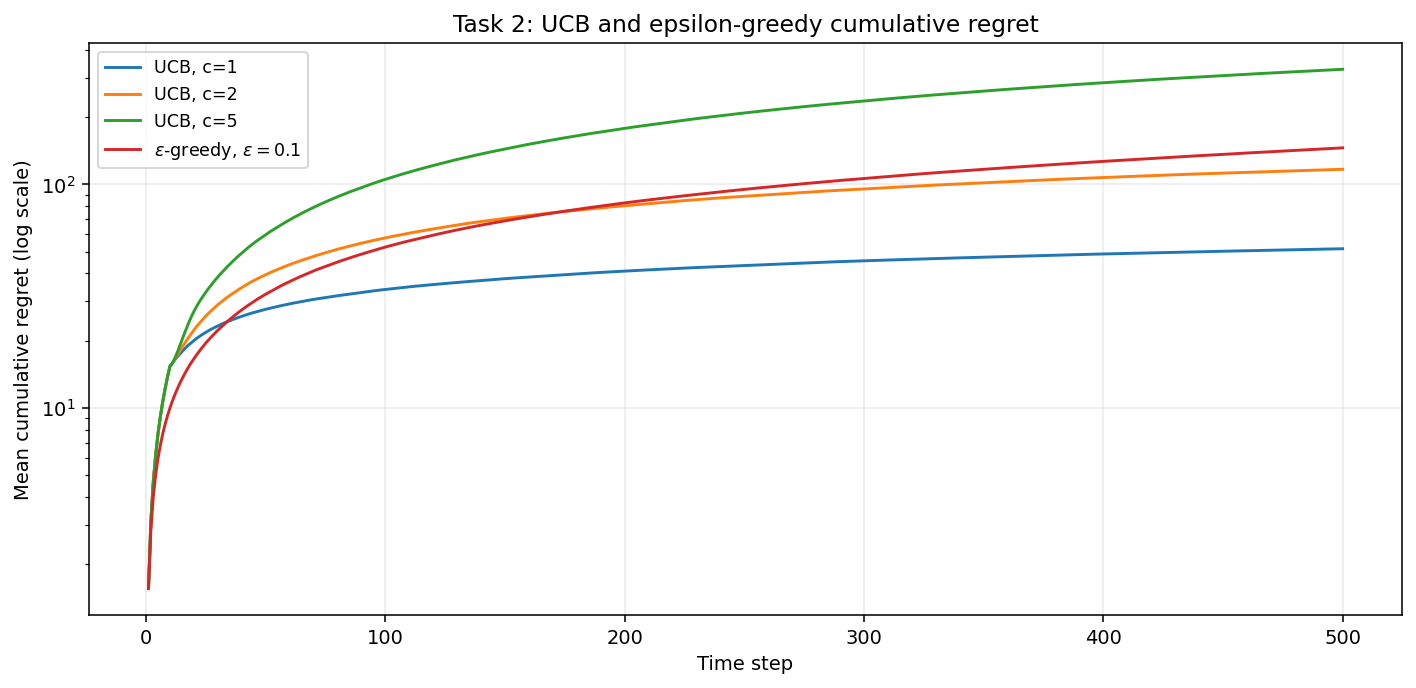

method | mean reward (1-500) | optimal actions (401-500) | mean cumulative regret at 500
                 UCB, c=1 |              1.4323 |                    89.05% |                      51.5363
                 UCB, c=2 |              1.3018 |                    79.69% |                     116.7982
                 UCB, c=5 |              0.8813 |                    51.80% |                     327.0401
epsilon-greedy, epsilon=0.1 |              1.2442 |                    75.36% |                     145.6227


In [8]:
q2_ucb_results = {}
for c in [1, 2, 5]:
    q2_ucb_results[f'UCB, c={c}'] = q2_value_run(q2_means, q2_noise, 'ucb', c)
q2_ucb_results[r'$\varepsilon$-greedy, $\varepsilon=0.1$'] = q2_epsilon_results[r'$\varepsilon=0.1$']

q2_plot(q2_ucb_results, 'average_reward',
        'Task 2: UCB and epsilon-greedy average reward', 'Average reward across runs',
        'task_2/average_reward.png')
q2_plot(q2_ucb_results, 'optimal_percent',
        'Task 2: UCB and epsilon-greedy optimal actions', 'Optimal action (%) across runs',
        'task_2/optimal_actions.png')
q2_plot(q2_ucb_results, 'cumulative_regret',
        'Task 2: UCB and epsilon-greedy cumulative regret', 'Mean cumulative regret (log scale)',
        'task_2/cumulative_regret.png', log_scale=True)

print('method | mean reward (1-500) | optimal actions (401-500) | mean cumulative regret at 500')
for label, result in q2_ucb_results.items():
    name = label if label.startswith('UCB') else 'epsilon-greedy, epsilon=0.1'
    print(f'{name:>25} | {result["average_reward"].mean():>19.4f} | '
          f'{result["optimal_percent"][-100:].mean():>24.2f}% | '
          f'{result["cumulative_regret"][-1]:>28.4f}')


**“How does $c$ influence exploration?”**

The constant $c$ scales UCB's uncertainty bonus, $c\sqrt{\ln t/N_t(a)}$. Larger values encourage more selections of lightly sampled arms; smaller values favor current reward estimates but can be more vulnerable to estimation errors. Untried arms receive priority, with random tie-breaking, so each arm is sampled once before the regular bonus is used. UCB then directs exploration according to estimated value and uncertainty, rather than choosing uniformly at a fixed rate.

**“Does UCB achieve lower regret than $\varepsilon$-greedy?”**

As the cumulative-regret plot and summary above show, **UCB with $c=1$ and $c=2$ achieves lower regret** than $\varepsilon$-greedy with $\varepsilon=0.1$. The best tested setting is $c=1$, whereas $c=5$ explores too aggressively and has higher regret over the 500-step horizon. UCB therefore does not outperform the comparison method for every parameter value.

Regret uses the gap between the optimal and selected arms' true means, not the noisy observed reward. The plotted cumulative regret averages those accumulated gaps across runs. Lower curves mean less reward lost through suboptimal choices; cumulative regret cannot decrease because every gap is nonnegative. The logarithmic vertical axis helps compare their growth.

**“Describe early-time and asymptotic behavior of both methods.”**

Initially, UCB pays the cost of trying every arm. The transition to bonus-driven selection can produce short transients, especially for large $c$. The $\varepsilon$-greedy learner can exploit promising observations sooner, but those observations can be misleading. In the plots, $c=1$ concentrates on optimal actions relatively quickly, while larger values improve more slowly.

Over long horizons, fixed-$\varepsilon$ exploration retains a positive per-step regret even with perfect identification:

$$
\varepsilon\left(q_*(a^*)-\frac{1}{10}\sum_a q_*(a)\right).
$$

This gives cumulative regret a linear component. UCB can instead make exploration a diminishing fraction of selections, because its bonus shrinks with observations and grows only logarithmically with time for neglected arms. With suitable confidence calibration, it can achieve sublinear regret, often logarithmic for a fixed problem. These finite-horizon plots support the observed ranking but do not establish an asymptotic guarantee for every tested $c$.


### Task 3 — Gradient Bandit and Baseline Analysis

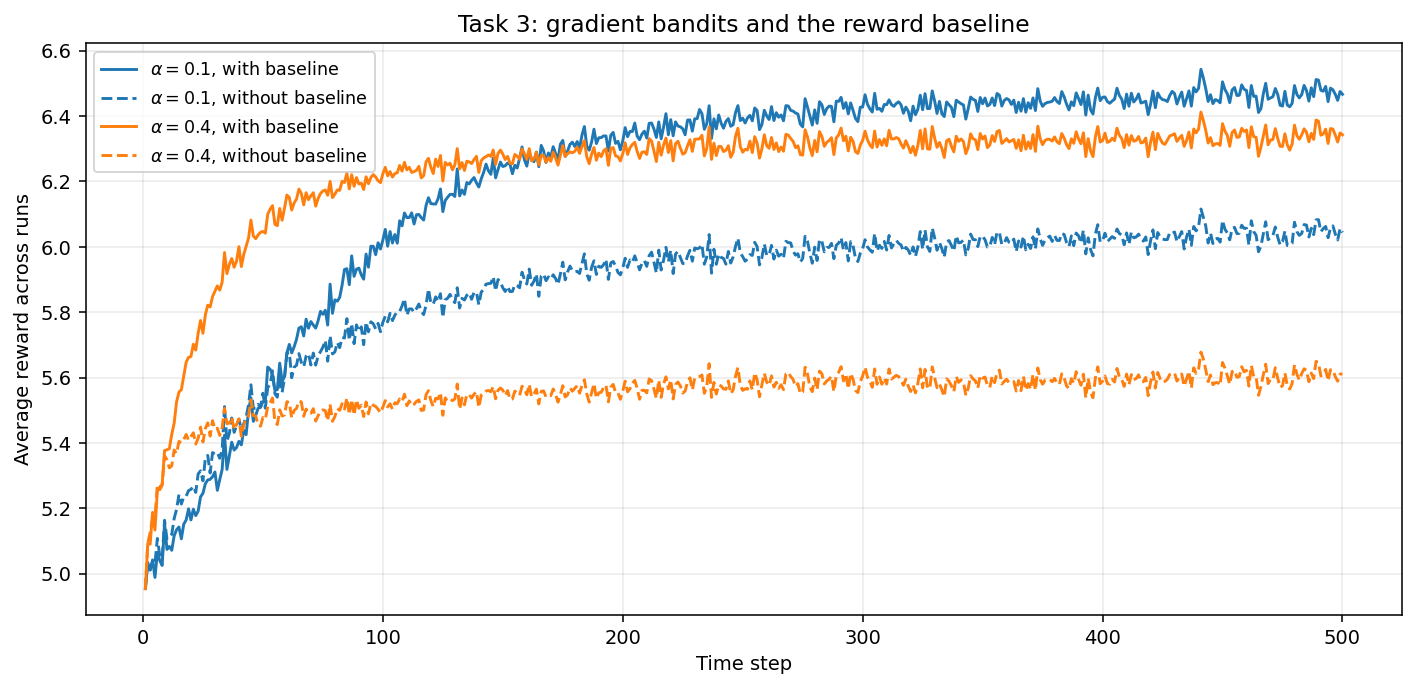

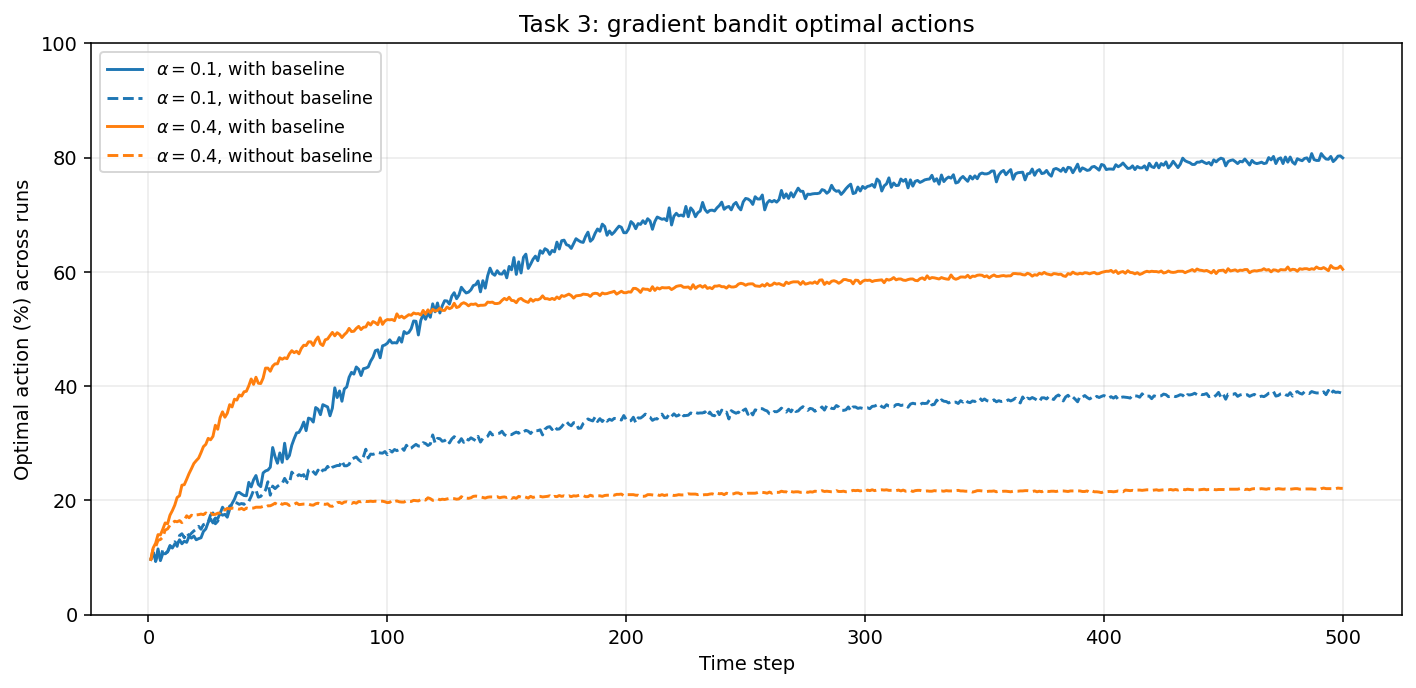

alpha | baseline | mean reward (1-500) | mean reward (401-500) | optimal actions (401-500)
  0.1 |      yes |              6.2075 |                6.4617 |                    79.16%
  0.1 |       no |              5.8785 |                6.0378 |                    38.45%
  0.4 |      yes |              6.2322 |                6.3354 |                    60.22%
  0.4 |       no |              5.5523 |                5.6026 |                    21.90%


In [9]:
q2_gradient_means = q2_means + 5.0
q2_gradient_results = {}
for alpha, color in [(0.1, 'tab:blue'), (0.4, 'tab:orange')]:
    for use_baseline in [True, False]:
        condition = 'with baseline' if use_baseline else 'without baseline'
        label = rf'$\alpha={alpha:g}$, {condition}'
        result = q2_gradient_run(q2_gradient_means, q2_noise, alpha, use_baseline)
        result['style'] = {'color': color, 'linestyle': '-' if use_baseline else '--'}
        q2_gradient_results[label] = result

q2_plot(q2_gradient_results, 'average_reward',
        'Task 3: gradient bandits and the reward baseline', 'Average reward across runs',
        'task_3/average_reward.png')
q2_plot(q2_gradient_results, 'optimal_percent',
        'Task 3: gradient bandit optimal actions', 'Optimal action (%) across runs',
        'task_3/optimal_actions.png')

print('alpha | baseline | mean reward (1-500) | mean reward (401-500) | optimal actions (401-500)')
for (alpha, baseline), result in zip(
        [(0.1, 'yes'), (0.1, 'no'), (0.4, 'yes'), (0.4, 'no')], q2_gradient_results.values()):
    print(f'{alpha:>5g} | {baseline:>8} | {result["average_reward"].mean():>19.4f} | '
          f'{result["average_reward"][-100:].mean():>21.4f} | '
          f'{result["optimal_percent"][-100:].mean():>24.2f}%')


**“How does the baseline affect learning stability and variance?”**

The running baseline centers the update signal, $R_t-b_t$, around the learner's recent reward level. A positive reward can then discourage the selected action if it was worse than usual. Without the baseline, the reward offset near 5 makes most rewards positive, often strongly reinforcing whichever action was sampled, including mediocre choices. This can produce variable updates and premature concentration on a suboptimal action.

The baseline uses rewards observed before the current step and is updated afterward. Because it is action-independent, it leaves the expected gradient unchanged:

$$
\mathbb E\!\left[b_t\bigl(\mathbb I_{a=A_t}-\pi_t(a)\bigr)\mid\text{past}\right]=0.
$$

A suitable baseline can reduce gradient-estimation variance; the running reward average is a practical choice rather than a guarantee of minimum variance at every step. As we see above, including it improves reward and optimal-action selection for both tested step sizes.

**“How does $\alpha$ influence convergence speed and smoothness?”**

A larger $\alpha$ produces stronger changes in preferences and action probabilities. It can accelerate initial learning, but also increases sensitivity to reward noise and the risk of prematurely favoring an action. Smaller steps change the policy more gradually. The smoothness of an across-run average curve alone is not a direct measure of an individual learner's update variance.

With the baseline, $\alpha=0.4$ improves faster initially and has a slightly higher full-horizon average reward. However, $\alpha=0.1$ overtakes it later and gives the stronger late-stage policy. Without the baseline, increasing $\alpha$ to 0.4 worsens performance because the large positive reward offset drives more aggressive preference changes. These results distinguish faster initial improvement from better final decision quality, while showing why the baseline matters at both step sizes.
